In [1]:
import os
import shutil
import warnings
warnings.filterwarnings('ignore')  

file_count = sum(len(filenames) for _, _, filenames in os.walk('/kaggle/input'))
print(f"Number of files in the input folder: {file_count}")

folder_to_clear = '/kaggle/working/'
if os.path.exists(folder_to_clear):
    for filename in os.listdir(folder_to_clear):
        file_path = os.path.join(folder_to_clear, filename)
        if os.path.isfile(file_path) or os.path.islink(file_path):
            os.unlink(file_path)
        elif os.path.isdir(file_path):
            shutil.rmtree(file_path)
print("Working folder cleared successfully.")

Number of files in the input folder: 1908
Working folder cleared successfully.


In [2]:
from PIL import Image

folder_path = '/kaggle/input/weed-detection/train'
file_count = len([f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))])
print(f"Number of files in {folder_path}: {file_count}")

source_dir = "/kaggle/input/weed-detection/train"
destination_dir = "/kaggle/working/"
os.makedirs(destination_dir, exist_ok=True)

for root, _, files in os.walk(source_dir):
    for file in files:
        file_path = os.path.join(root, file)
        try:
            with Image.open(file_path) as img:
                img.verify()  
        except (IOError, SyntaxError):
            shutil.copy(file_path, destination_dir)
            print(f"Copied non-image file: {file_path}")

Number of files in /kaggle/input/weed-detection/train: 1662
Copied non-image file: /kaggle/input/weed-detection/train/_annotations.coco.json


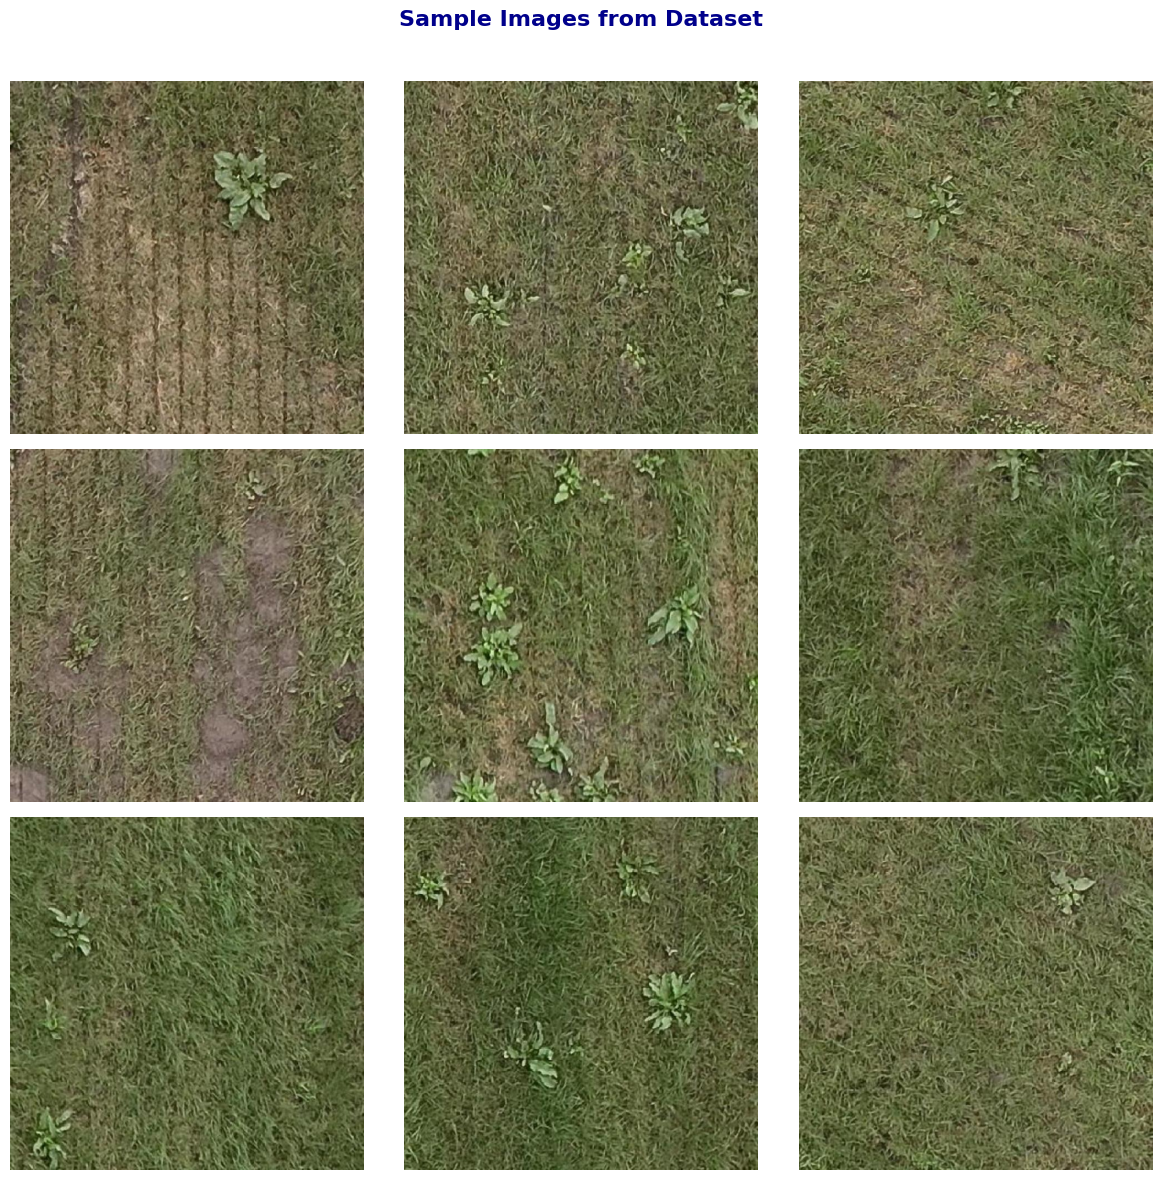

In [3]:
import os
import matplotlib.pyplot as plt
from PIL import Image

if not os.path.exists(source_dir):
    print(f"Source directory '{source_dir}' does not exist.")
else:
    image_files = [f for f in os.listdir(source_dir) if os.path.isfile(os.path.join(source_dir, f))]

    num_images = min(9, len(image_files))
    
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    fig.suptitle("Sample Images from Dataset", fontsize=16, fontweight='bold', color='darkblue')

    for i, ax in enumerate(axes.flat):
        if i < num_images:
            img_path = os.path.join(source_dir, image_files[i])
            try:
                with Image.open(img_path) as img:
                    ax.imshow(img)
                    ax.axis("off")  
                    ax.set_frame_on(True)  
            except (IOError, SyntaxError):
                ax.axis("off")
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.92) 
    plt.show()

In [4]:
import json
from tqdm import tqdm

annotations_file = "/kaggle/working/_annotations.coco.json"
with open(annotations_file, 'r') as f:
    coco_data = json.load(f)

categories = coco_data.get("categories", [])
num_classes = len(categories)
class_names = [category['name'] for category in categories]
print(f"Number of Classes: {num_classes}")
print("Class Names:", class_names)

images_dir = "/kaggle/input/weed-detection/train"
output_dir = "/kaggle/working/yolo_format"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(f"{output_dir}/images", exist_ok=True)
os.makedirs(f"{output_dir}/labels", exist_ok=True)

category_id_to_class_id = {cat["id"]: idx for idx, cat in enumerate(categories)}
errors = []

for annotation in tqdm(coco_data["annotations"], desc="Converting annotations"):
    try:
        image_id = annotation["image_id"]
        bbox = annotation["bbox"]
        category_id = annotation["category_id"]
        image_info = next(img for img in coco_data["images"] if img["id"] == image_id)
        img_filename = image_info["file_name"]
        img_width = image_info["width"]
        img_height = image_info["height"]

        x_min, y_min, width, height = bbox
        x_center = (x_min + width / 2) / img_width
        y_center = (y_min + height / 2) / img_height
        norm_width = width / img_width
        norm_height = height / img_height

        class_id = category_id_to_class_id[category_id]
        yolo_line = f"{class_id} {x_center} {y_center} {norm_width} {norm_height}\n"

        txt_filename = os.path.splitext(img_filename)[0] + ".txt"
        with open(os.path.join(output_dir, "labels", txt_filename), "a") as f:
            f.write(yolo_line)

        shutil.copy(os.path.join(images_dir, img_filename), os.path.join(output_dir, "images", img_filename))
    except Exception as e:
        errors.append((annotation, str(e)))

print(f"Conversion completed with {len(errors)} errors.")

Number of Classes: 2
Class Names: ['grass-weeds', '0 ridderzuring']


Converting annotations: 100%|██████████| 4199/4199 [00:10<00:00, 389.13it/s]

Conversion completed with 0 errors.


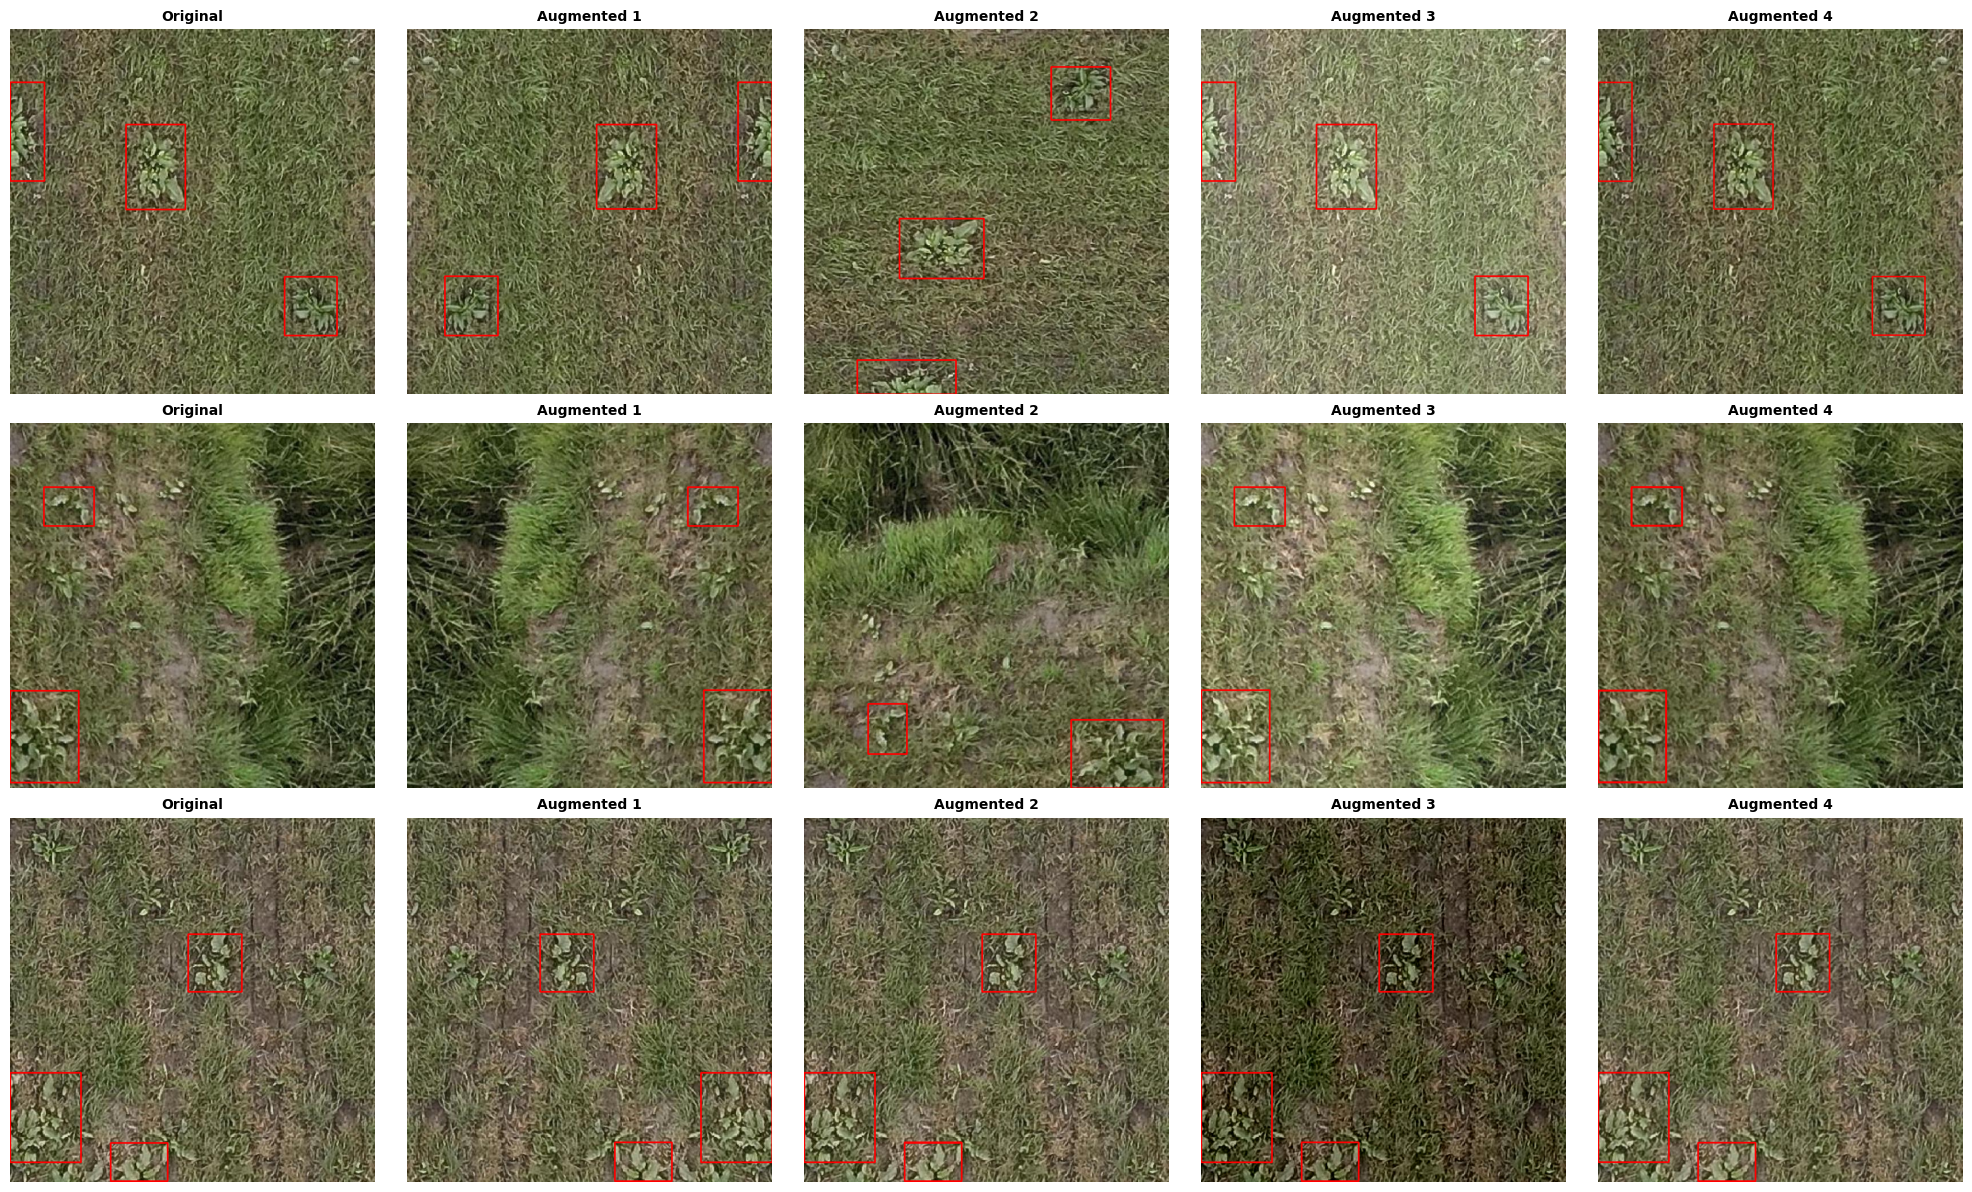

In [5]:
import os
import cv2
import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import random
import math

transformations = [
    A.Compose([A.HorizontalFlip(p=1.0)], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels'])),  # انعكاس أفقي
    A.Compose([A.RandomRotate90(p=1.0)], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels'])),   # تدوير 90 درجة
    A.Compose([A.RandomBrightnessContrast(p=1.0)], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels'])),  # تغيير السطوع والتباين
    A.Compose([A.RandomScale(scale_limit=0.2, p=1.0)], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels']))  # تكبير عشوائي
]

images_dir = '/kaggle/working/yolo_format/images'
labels_dir = '/kaggle/working/yolo_format/labels'
output_images_dir = '/kaggle/working/yolo_format/augmented_images'
output_labels_dir = '/kaggle/working/yolo_format/augmented_labels'

os.makedirs(output_images_dir, exist_ok=True)
os.makedirs(output_labels_dir, exist_ok=True)

image_files = [f for f in os.listdir(images_dir) if f.endswith('.jpg') or f.endswith('.png')]

all_images = []  
for image_file in image_files:
    image_path = os.path.join(images_dir, image_file)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) 

    label_file = os.path.splitext(image_file)[0] + '.txt'
    label_path = os.path.join(labels_dir, label_file)
    
    with open(label_path, 'r') as f:
        lines = f.readlines()

    bboxes = []
    class_labels = []
    for line in lines:
        class_id, x_center, y_center, width, height = map(float, line.strip().split())
        bboxes.append([x_center, y_center, width, height])
        class_labels.append(class_id)

    all_images.append((image, bboxes, "Original"))

    for i, transform in enumerate(transformations):
        transformed = transform(image=image, bboxes=bboxes, class_labels=class_labels)
        transformed_image = transformed['image']
        transformed_bboxes = transformed['bboxes']
        transformed_class_labels = transformed['class_labels']


        augmented_image_path = os.path.join(output_images_dir, f"aug_{i}_{image_file}")
        cv2.imwrite(augmented_image_path, cv2.cvtColor(transformed_image, cv2.COLOR_RGB2BGR))

        augmented_label_path = os.path.join(output_labels_dir, f"aug_{i}_{label_file}")
        with open(augmented_label_path, 'w') as f:
            for bbox, class_id in zip(transformed_bboxes, transformed_class_labels):
                f.write(f"{int(class_id)} {' '.join(map(str, bbox))}\n")

        all_images.append((transformed_image, transformed_bboxes, f"Augmented {i+1}"))

num_images = len(all_images)
num_cols = len(transformations) + 1  
num_rows = len(image_files[:3])  

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 4, num_rows * 4))

for i in range(num_rows):
    for j in range(num_cols):
        img, bboxes, title = all_images[i * num_cols + j]
        
        for bbox in bboxes:
            x_center, y_center, width, height = bbox
            x_min = int((x_center - width / 2) * img.shape[1])
            y_min = int((y_center - height / 2) * img.shape[0])
            x_max = int((x_center + width / 2) * img.shape[1])
            y_max = int((y_center + height / 2) * img.shape[0])
            cv2.rectangle(img, (x_min, y_min), (x_max, y_max), (255, 0, 0), 2)
        
        axes[i, j].imshow(img)
        axes[i, j].set_title(title, fontsize=10, fontweight="bold")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [6]:
original_image_count = len([f for f in os.listdir(images_dir) if f.endswith(('.jpg', '.png'))])
print(f"Number of original images: {original_image_count}")

augmented_image_count = len([f for f in os.listdir(output_images_dir) if f.endswith(('.jpg', '.png'))])
print(f"Number of enhanced images: {augmented_image_count}")

total_images = original_image_count + augmented_image_count
print(f"Total number of photos after editing: {total_images}")

Number of original images: 1655
Number of enhanced images: 6620
Total number of photos after editing: 8275


In [7]:
import os
import shutil
from sklearn.model_selection import train_test_split

original_images_dir = '/kaggle/working/yolo_format/images'
augmented_images_dir = '/kaggle/working/yolo_format/augmented_images'
original_labels_dir = '/kaggle/working/yolo_format/labels'
augmented_labels_dir = '/kaggle/working/yolo_format/augmented_labels'

output_dir = '/kaggle/working/dataset'

original_images = [f for f in os.listdir(original_images_dir) if f.endswith(('.jpg', '.png'))]
augmented_images = [f for f in os.listdir(augmented_images_dir) if f.endswith(('.jpg', '.png'))]
all_images = original_images + augmented_images
original_labels = [f for f in os.listdir(original_labels_dir) if f.endswith('.txt')]
augmented_labels = [f for f in os.listdir(augmented_labels_dir) if f.endswith('.txt')]
all_labels = original_labels + augmented_labels
train_images, val_images = train_test_split(all_images, test_size=0.2, random_state=42)

train_dir = os.path.join(output_dir, 'images/train')
val_dir = os.path.join(output_dir, 'images/val')
train_labels_dir = os.path.join(output_dir, 'labels/train')
val_labels_dir = os.path.join(output_dir, 'labels/val')

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)
os.makedirs(train_labels_dir, exist_ok=True)
os.makedirs(val_labels_dir, exist_ok=True)

def copy_files(image_list, src_img_dir1, src_img_dir2, src_lbl_dir1, src_lbl_dir2, dest_img_dir, dest_lbl_dir):
    for image_file in image_list:
        if image_file in original_images:
            src_img = os.path.join(src_img_dir1, image_file)
            src_lbl = os.path.join(src_lbl_dir1, os.path.splitext(image_file)[0] + ".txt")
        else:
            src_img = os.path.join(src_img_dir2, image_file)
            src_lbl = os.path.join(src_lbl_dir2, os.path.splitext(image_file)[0] + ".txt")

        shutil.copy(src_img, os.path.join(dest_img_dir, image_file))

        if os.path.exists(src_lbl):
            shutil.copy(src_lbl, os.path.join(dest_lbl_dir, os.path.basename(src_lbl)))

copy_files(train_images, original_images_dir, augmented_images_dir, original_labels_dir, augmented_labels_dir, train_dir, train_labels_dir)
copy_files(val_images, original_images_dir, augmented_images_dir, original_labels_dir, augmented_labels_dir, val_dir, val_labels_dir)
print(f"The database is successfully equipped: {len(train_images)} Picture of the training and {len(val_images)} Photo for verification.")

The database is successfully equipped: 6620 Picture of the training and 1655 Photo for verification.


In [8]:
import yaml
yaml_path = '/kaggle/working/dataset.yaml'
dataset_config = {
    "path": "/kaggle/working/dataset",
    "train": "images/train",
    "val": "images/val",
    "nc": num_classes,
    "names": class_names
}

with open(yaml_path, 'w') as f:
    yaml.dump(dataset_config, f, default_flow_style=False, allow_unicode=True)

print(f"YAML file successfully created: {yaml_path}")

YAML file successfully created: /kaggle/working/dataset.yaml


In [9]:
!pip install ultralytics
from ultralytics import YOLO

model = YOLO('yolov8s.pt')  

model.train(data=yaml_path, epochs=170, imgsz=640, batch=16, name="yolov8_nano_custom")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 922.1/922.1 kB 20.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 21.5M/21.5M [00:00<00:00, 114MB/s] 


Ultralytics 8.3.81 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/kaggle/working/dataset.yaml, epochs=170, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=yolov8_nano_custom, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True

100%|██████████| 755k/755k [00:00<00:00, 27.3MB/s]


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.C2f             [256, 256, 2, True]           
  7                  -1  1   1180672  ultralytics

...

                   all       1655       4250      0.961      0.911      0.951      0.811



170 epochs completed in 6.518 hours.
Optimizer stripped from runs/detect/yolov8_nano_custom/weights/last.pt, 22.5MB
Optimizer stripped from runs/detect/yolov8_nano_custom/weights/best.pt, 22.5MB

Validating runs/detect/yolov8_nano_custom/weights/best.pt...
Ultralytics 8.3.81 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 52/52 [00:14<00:00,  3.47it/s]


                   all       1655       4250      0.961      0.911      0.951      0.811
        0 ridderzuring       1655       4250      0.961      0.911      0.951      0.811
Speed: 0.2ms preprocess, 4.4ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to runs/detect/yolov8_nano_custom


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x788bda2e3370>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [10]:
model_save_path = "/kaggle/working/runs/detect/yolov8_nano_custom/best.pt"

In [11]:
metrics = model.val(data=yaml_path)

print(f"Precision: {metrics.results_dict['metrics/precision(B)']}")
print(f"Recall: {metrics.results_dict['metrics/recall(B)']}")
print(f"mAP50: {metrics.results_dict['metrics/mAP50(B)']}")
print(f"mAP50-95: {metrics.results_dict['metrics/mAP50-95(B)']}")

Ultralytics 8.3.81 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs


val: Scanning /kaggle/working/dataset/labels/val.cache... 1655 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1655/1655 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 104/104 [00:16<00:00,  6.48it/s]


                   all       1655       4250      0.961      0.911      0.951      0.811
        0 ridderzuring       1655       4250      0.961      0.911      0.951      0.811
Speed: 0.4ms preprocess, 4.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to runs/detect/yolov8_nano_custom2
Precision: 0.9605941406144745
Recall: 0.9105882352941177
mAP50: 0.9511939301072305
mAP50-95: 0.8113611446901657


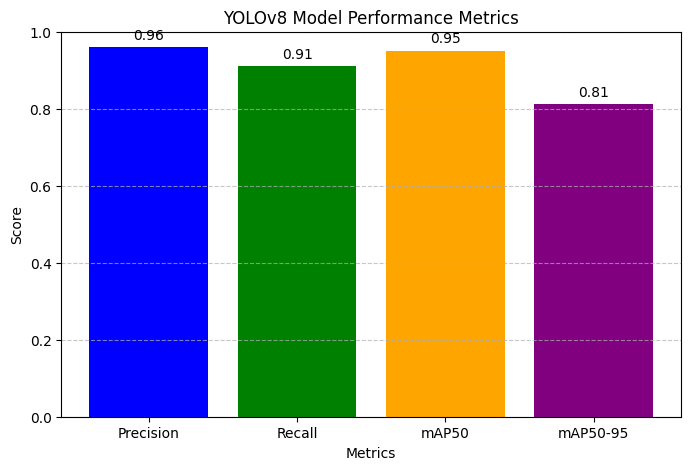

In [12]:
import matplotlib.pyplot as plt
%matplotlib inline

precision = metrics.results_dict['metrics/precision(B)']
recall = metrics.results_dict['metrics/recall(B)']
map50 = metrics.results_dict['metrics/mAP50(B)']
map5095 = metrics.results_dict['metrics/mAP50-95(B)']

metrics_names = ['Precision', 'Recall', 'mAP50', 'mAP50-95']
metrics_values = [precision, recall, map50, map5095]

plt.figure(figsize=(8, 5))
plt.bar(metrics_names, metrics_values, color=['blue', 'green', 'orange', 'purple'])
plt.ylim(0, 1)
plt.title("YOLOv8 Model Performance Metrics")
plt.ylabel("Score")
plt.xlabel("Metrics")
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, v in enumerate(metrics_values):
        plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontsize=10)

plt.show()


image 1/1 /kaggle/input/weed-detection/test/ridderzuring_3151_jpg.rf.175e23691b2ce606f3054d24896fd639.jpg: 640x640 7 0 ridderzurings, 9.9ms
Speed: 2.5ms preprocess, 9.9ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


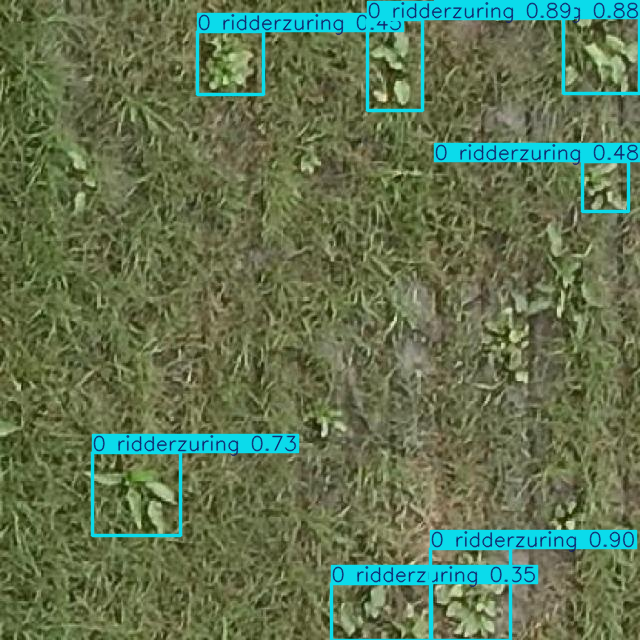

Predicted image saved to: /kaggle/working/predicted_image.jpg


In [13]:
image_path = '/kaggle/input/weed-detection/test/ridderzuring_3151_jpg.rf.175e23691b2ce606f3054d24896fd639.jpg'  
predictions = model(image_path)
predictions[0].show()
output_image_path = '/kaggle/working/predicted_image.jpg' 
predictions[0].save(output_image_path)

print(f"Predicted image saved to: {output_image_path}")

In [14]:
for box in predictions[0].boxes:
    print(f"Class: {box.cls}, Confidence: {box.conf}, Coordinates: {box.xywh}")

Class: tensor([1.], device='cuda:0'), Confidence: tensor([0.8979], device='cuda:0'), Coordinates: tensor([[470.2575, 594.1682,  80.1410,  91.6636]], device='cuda:0')
Class: tensor([1.], device='cuda:0'), Confidence: tensor([0.8857], device='cuda:0'), Coordinates: tensor([[395.2790,  64.7232,  55.3811,  91.3322]], device='cuda:0')
Class: tensor([1.], device='cuda:0'), Confidence: tensor([0.8751], device='cuda:0'), Coordinates: tensor([[601.7576,  46.8961,  76.4612,  93.7922]], device='cuda:0')
Class: tensor([1.], device='cuda:0'), Confidence: tensor([0.7344], device='cuda:0'), Coordinates: tensor([[136.7539, 493.9808,  87.6336,  82.7009]], device='cuda:0')
Class: tensor([1.], device='cuda:0'), Confidence: tensor([0.4753], device='cuda:0'), Coordinates: tensor([[605.7024, 186.5847,  46.5305,  50.5339]], device='cuda:0')
Class: tensor([1.], device='cuda:0'), Confidence: tensor([0.4533], device='cuda:0'), Coordinates: tensor([[230.4125,  63.0770,  65.8064,  62.6969]], device='cuda:0')
Clas

   epoch     time  train/box_loss  train/cls_loss  train/dfl_loss  \
0      1  145.090         1.86926         1.73765         1.60494   
1      2  284.303         1.70401         1.16865         1.46666   
2      3  422.135         1.71005         1.18690         1.46889   
3      4  559.722         1.73969         1.20627         1.50020   
4      5  697.441         1.72415         1.17288         1.49862   

   metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
0               0.77173            0.73820           0.78750   
1               0.76051            0.70086           0.77064   
2               0.74104            0.73012           0.76657   
3               0.77047            0.74565           0.79585   
4               0.76243            0.73459           0.78788   

   metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss    lr/pg0  \
0              0.38849       1.69285       0.97059       1.56727  0.003325   
1              0.38058       1.72691       1

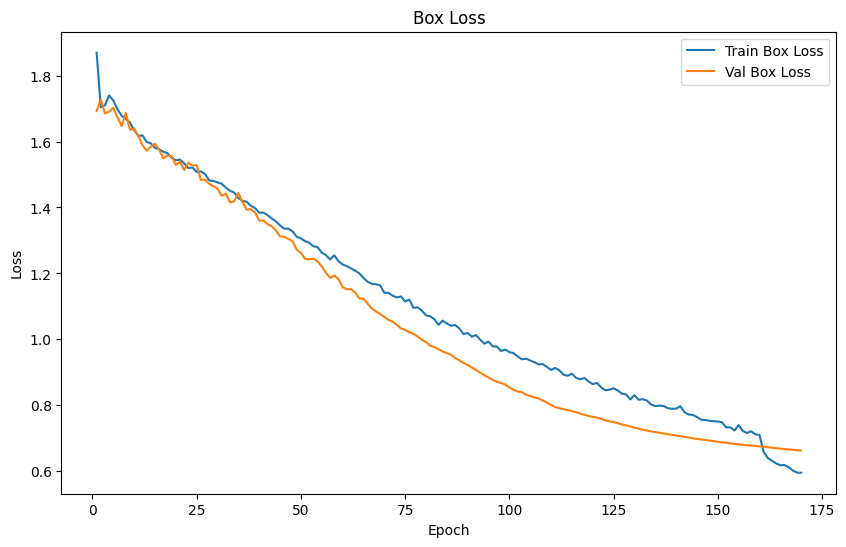

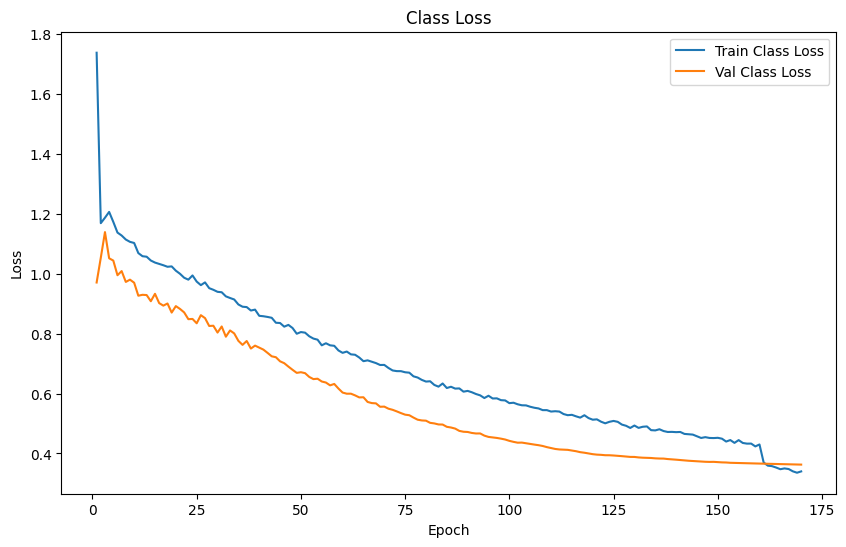

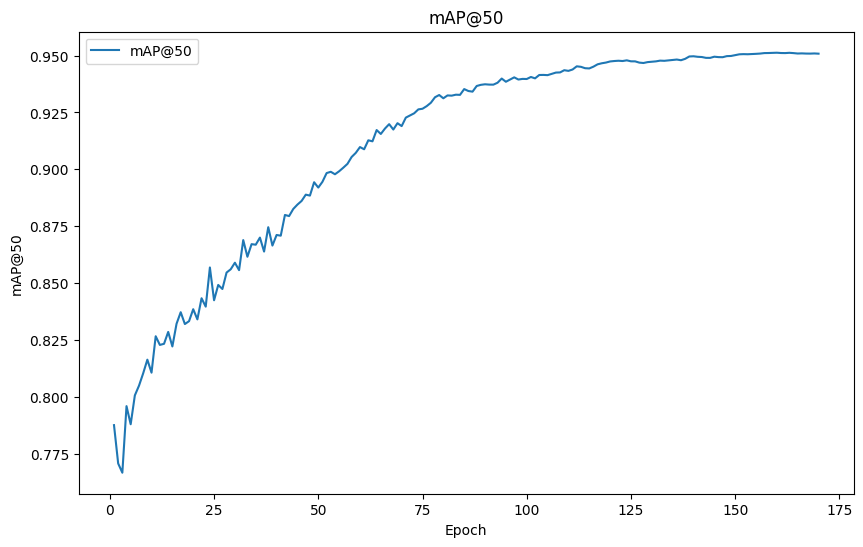

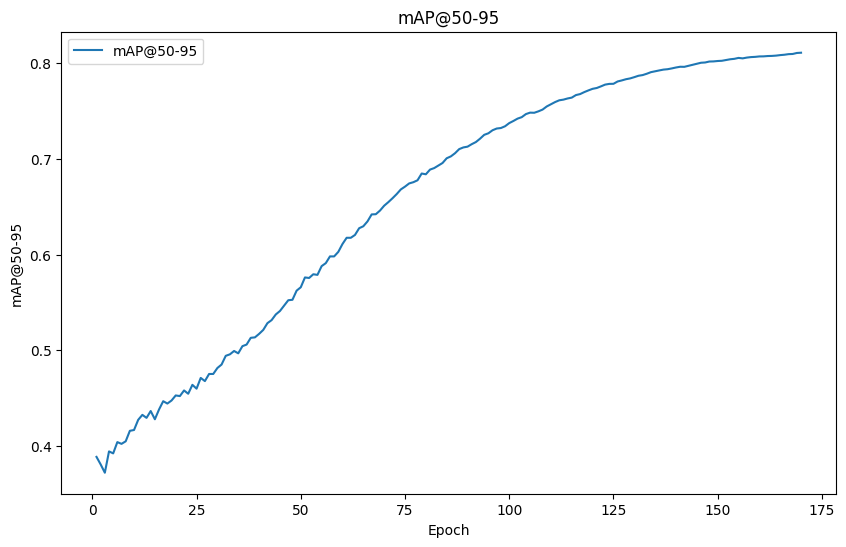

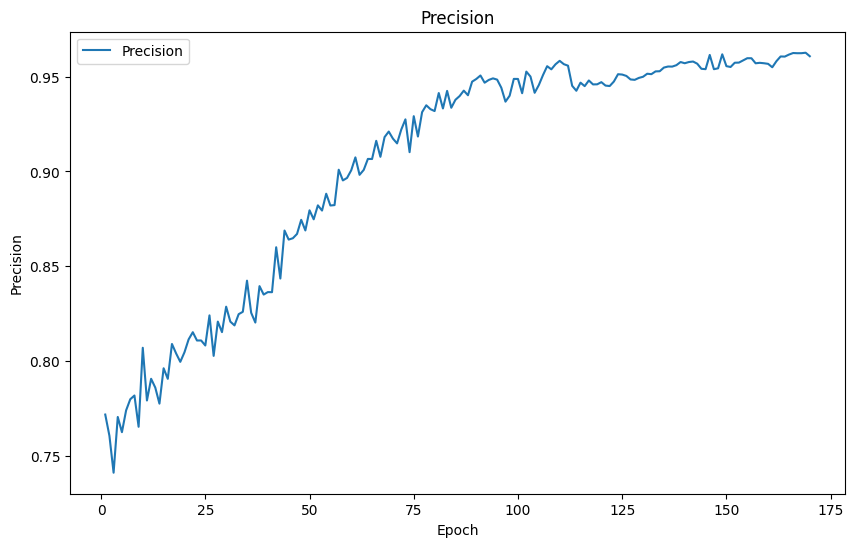

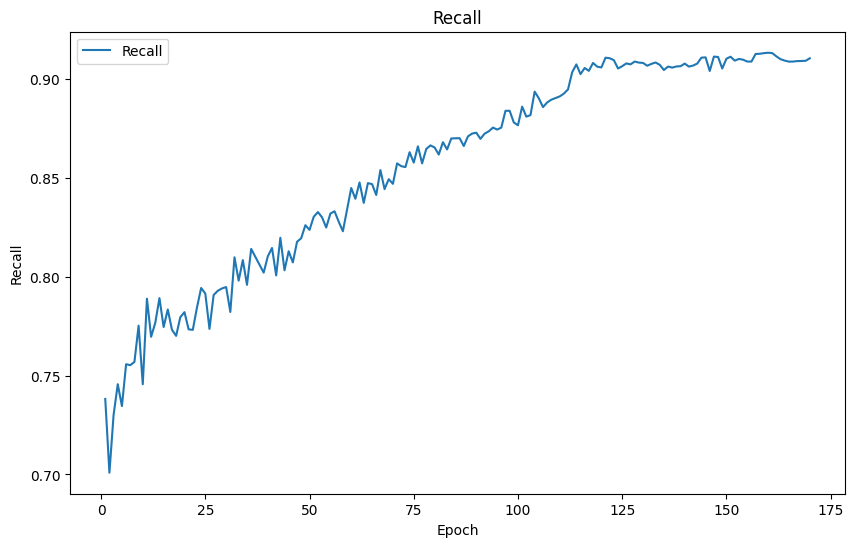

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = '/kaggle/working/runs/detect/yolov8_nano_custom/results.csv'

data = pd.read_csv(csv_path)

print(data.head())

plt.figure(figsize=(10, 6))
plt.plot(data['epoch'], data['train/box_loss'], label='Train Box Loss')
plt.plot(data['epoch'], data['val/box_loss'], label='Val Box Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Box Loss')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(data['epoch'], data['train/cls_loss'], label='Train Class Loss')
plt.plot(data['epoch'], data['val/cls_loss'], label='Val Class Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Class Loss')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(data['epoch'], data['metrics/mAP50(B)'], label='mAP@50')
plt.xlabel('Epoch')
plt.ylabel('mAP@50')
plt.title('mAP@50')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(data['epoch'], data['metrics/mAP50-95(B)'], label='mAP@50-95')
plt.xlabel('Epoch')
plt.ylabel('mAP@50-95')
plt.title('mAP@50-95')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(data['epoch'], data['metrics/precision(B)'], label='Precision')
plt.xlabel('Epoch')
plt.ylabel('Precision')
plt.title('Precision')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(data['epoch'], data['metrics/recall(B)'], label='Recall')
plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.title('Recall')
plt.legend()
plt.show()